In [ ]:
"C:\Users\manik\OneDrive\Desktop\Alfido-Tech-Internship\Website_Traffic_Analysis\data\traffic.csv"

In [6]:
# ================================
# PART 1
# MUSIC EVENT TRAFFIC ANALYSIS
# ================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")


# Load dataset
df = pd.read_csv(
    r"C:\Users\manik\OneDrive\Desktop\Alfido-Tech-Internship\Website_Traffic_Analysis\data\traffic.csv"
)


print("Dataset Shape:")
print(df.shape)


print("\nColumns:")
print(df.columns)


display(df.head())


# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())


# Remove duplicates

df.drop_duplicates(inplace=True)


# Fill missing values

for col in df.columns:

    if df[col].dtype == "object":
        df[col].fillna("Unknown", inplace=True)


# Convert date

df['date'] = pd.to_datetime(df['date'])


# Create time features

df['year'] = df['date'].dt.year

df['month'] = df['date'].dt.month

df['day'] = df['date'].dt.day


print("\nCleaning Completed")

df.head()

Dataset Shape:
(226278, 9)

Columns:
Index(['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc',
       'linkid'],
      dtype='object')


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8



Missing Values:
event         0
date          0
country      11
city         11
artist       37
album         5
track         5
isrc       7121
linkid        0
dtype: int64

Cleaning Completed


,event,date,country,city,artist,album,track,isrc,linkid,year,month,day
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8,2021,8,21
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2,2021,8,21
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd,2021,8,21
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8,2021,8,21
5,click,2021-08-21,United States,Los Angeles,KenTheMan,I'm Perfect,I'm Perfect,US39N2102090,190c7170-4044-4c97-9709-926917155b02,2021,8,21


Total Events: 122567
Unique Users: 3839


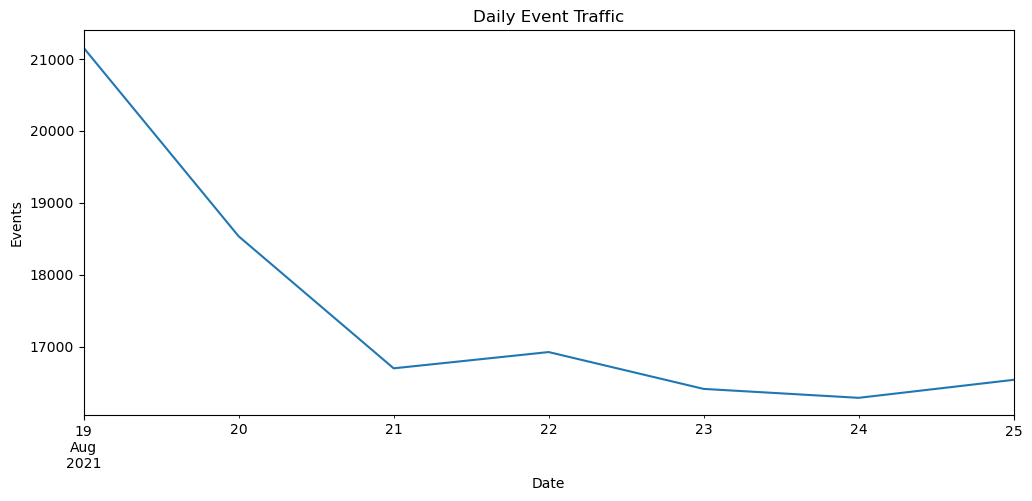

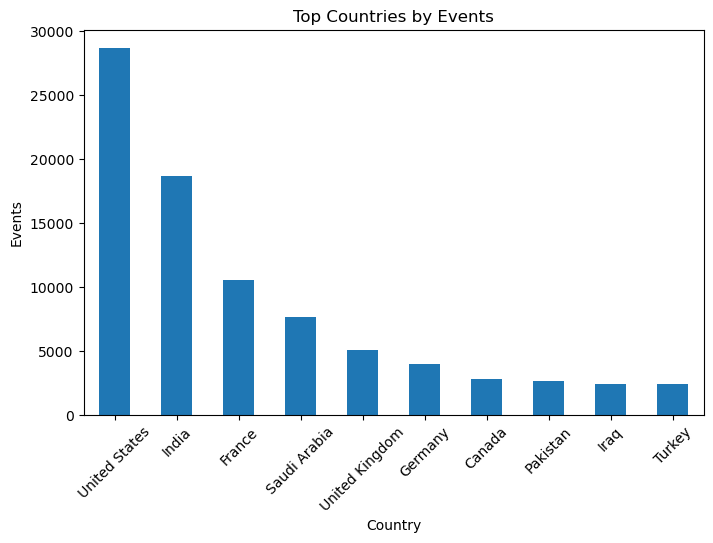

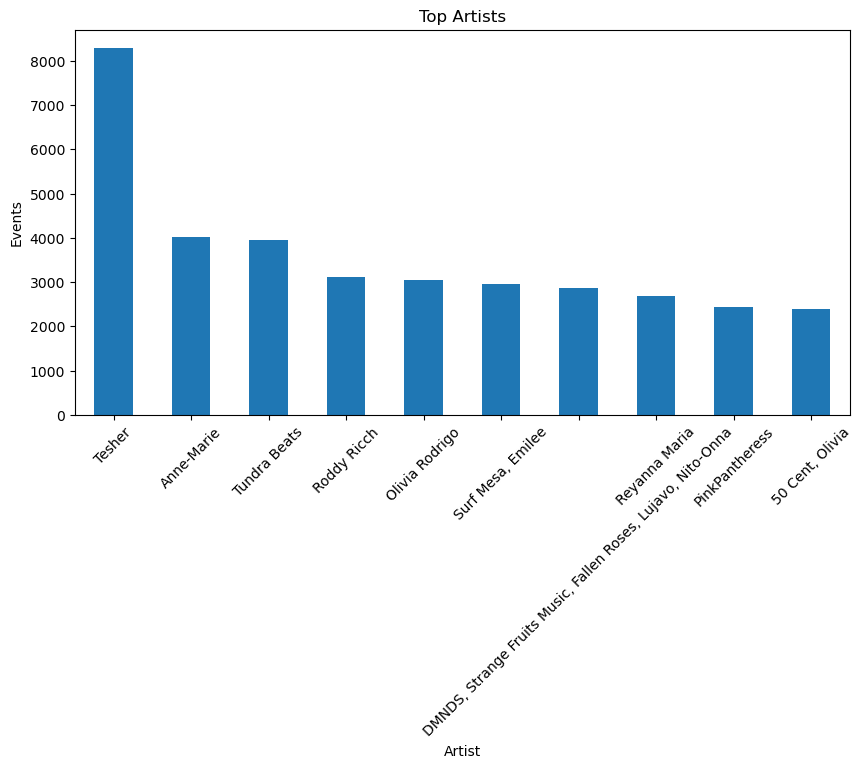

In [7]:
# ================================
# PART 2
# ANALYSIS AND VISUALIZATION
# ================================


# Total Events

total_events = len(df)


# Unique users (using linkid)

unique_users = df['linkid'].nunique()


print("Total Events:", total_events)

print("Unique Users:", unique_users)



# ================================
# Events Over Time
# ================================

daily_events = (
    df.groupby('date')
    .size()
)


plt.figure(figsize=(12,5))

daily_events.plot()

plt.title(
    "Daily Event Traffic"
)

plt.xlabel("Date")

plt.ylabel("Events")

plt.show()



# ================================
# Top Countries
# ================================

country = (
    df['country']
    .value_counts()
    .head(10)
)


plt.figure(figsize=(8,5))


country.plot(
    kind='bar'
)


plt.title(
    "Top Countries by Events"
)


plt.xlabel(
    "Country"
)


plt.ylabel(
    "Events"
)


plt.xticks(rotation=45)

plt.show()



# ================================
# Top Artists
# ================================

artists = (
    df['artist']
    .value_counts()
    .head(10)
)


plt.figure(figsize=(10,5))


artists.plot(
    kind='bar'
)


plt.title(
    "Top Artists"
)


plt.xlabel(
    "Artist"
)


plt.ylabel(
    "Events"
)


plt.xticks(rotation=45)

plt.show()

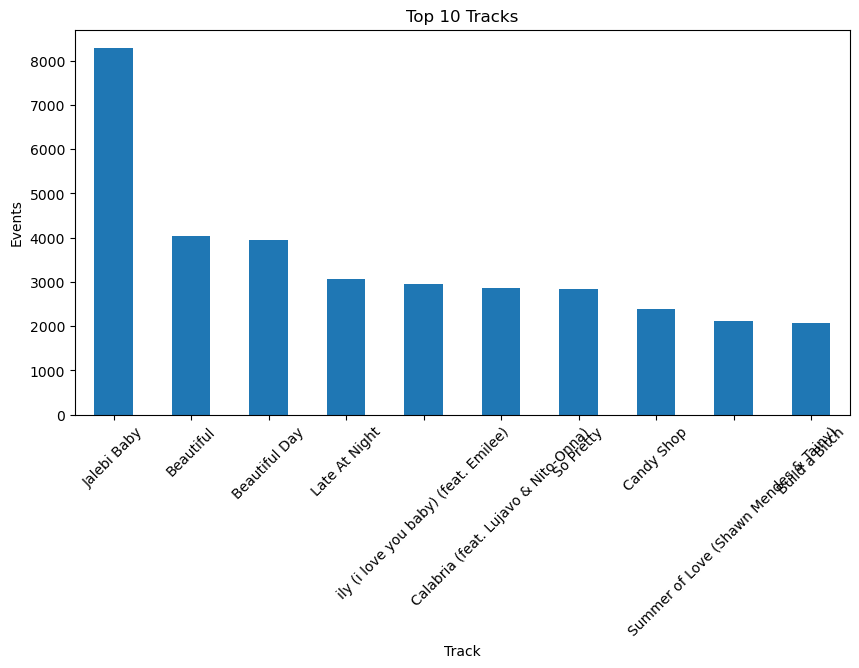

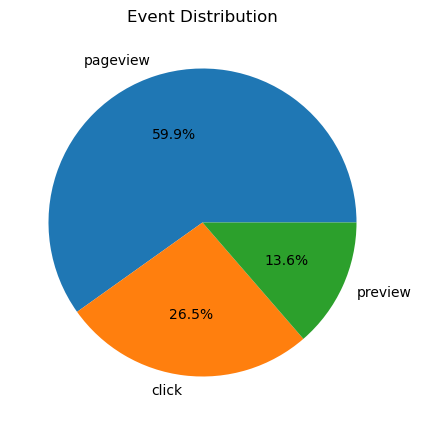

In [ ]:
# ================================
# PART 3
# FINAL INSIGHTS
# ================================


# Top Tracks

tracks = (
    df['track']
    .value_counts()
    .head(10)
)


plt.figure(figsize=(10,5))


tracks.plot(
    kind='bar'
)


plt.title(
    "Top 10 Tracks"
)


plt.xlabel(
    "Track"
)


plt.ylabel(
    "Events"
)


plt.xticks(rotation=45)

plt.show()



# Event Type Analysis

event_analysis = (
    df['event']
    .value_counts()
)


plt.figure(figsize=(7,5))


event_analysis.plot(
    kind='pie',
    autopct='%1.1f%%'
)


plt.title(
    "Event Distribution"
)


plt.ylabel("")


plt.show()



# Final KPI Report

report = pd.DataFrame({

    "Metric":[
        "Total Events",
        "Unique Users",
        "Countries",
        "Artists",
        "Tracks"
    ],

    "Value":[
        total_events,
        unique_users,
        df['country'].nunique(),
        df['artist'].nunique(),
        df['track'].nunique()
    ]

})


display(report)



# Save files

df.to_csv(
    "cleaned_music_traffic_data.csv",
    index=False
)


report.to_csv(
    "traffic_analysis_report.csv",
    index=False
)


print("Export Completed")